# CS 6220 Data Mining Homework 3
**Name:** Rutuja Jadhav

## Part 1: K-Nearest Neighbor

### Generate the dataset

X dtype/shape: float64 (200, 2)
y dtype/shape: int64 (200,)


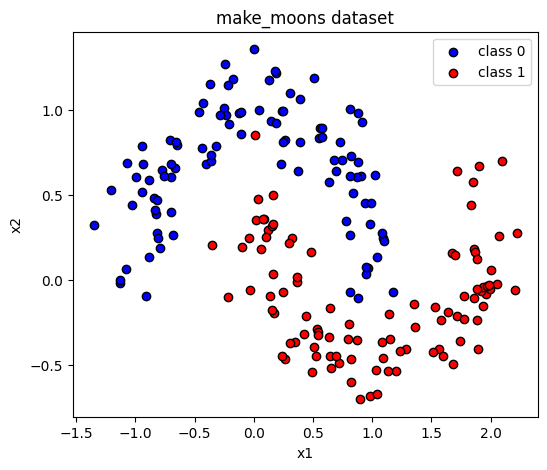

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.datasets import make_moons

# Generate the dataset (everyone uses the same seed for consistency)
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)

print("X dtype/shape:", X.dtype, X.shape)
print("y dtype/shape:", y.dtype, y.shape)

plt.figure(figsize=(6,5))
plt.scatter(X[y==0][:,0], X[y==0][:,1], c='blue', label='class 0', edgecolor='k')
plt.scatter(X[y==1][:,0], X[y==1][:,1], c='red', label='class 1', edgecolor='k')
plt.xlabel('x1'); plt.ylabel('x2'); plt.legend(); plt.title('make_moons dataset')
plt.show()

### Distance function (general Lp norm)

Rather than writing separate Euclidean and Manhattan functions, we implement the general Lp norm, with `p` as a parameter: `p=1` gives Manhattan distance, `p=2` gives Euclidean distance.

In [ ]:
def lp_distance(v1, v2, p):
    """General Lp norm distance between two vectors. p=1 -> Manhattan, p=2 -> Euclidean."""
    v1 = np.asarray(v1)
    v2 = np.asarray(v2)
    return np.sum(np.abs(v1 - v2) ** p) ** (1 / p)

# convenience wrappers
euclidean = lambda v1, v2: lp_distance(v1, v2, p=2)
manhattan = lambda v1, v2: lp_distance(v1, v2, p=1)

# sanity check
print("Euclidean((0,0),(3,4)):", euclidean((0,0),(3,4)))   # expect 5.0
print("Manhattan((0,0),(3,4)):", manhattan((0,0),(3,4)))   # expect 7.0

Euclidean((0,0),(3,4)): 5.0
Manhattan((0,0),(3,4)): 7.0


### knn predict

Predicts the class of a single test record by:
1. Computing the distance from the test point to every training record.
2. Taking the `k` closest training records.
3. Majority-voting their labels.
4. Breaking ties (possible when `k` is even) by picking the tied class whose single closest member is nearest to the test point -- a tie-break that still uses real distance information, rather than an arbitrary default.

In [ ]:
def knn_predict(X_train, y_train, X_test, y_test, k, distance_func):

    # 1. compute distance from X_test to every training record
    distances = np.array([distance_func(X_test, x) for x in X_train])

    # 2. find indices of the k smallest distances
    nearest_idx = np.argsort(distances)[:k]
    nearest_labels = y_train[nearest_idx]
    nearest_distances = distances[nearest_idx]

    # 3. majority vote
    counts = Counter(nearest_labels)
    max_votes = max(counts.values())
    tied_classes = [cls for cls, cnt in counts.items() if cnt == max_votes]

    if len(tied_classes) == 1:
        return tied_classes[0]

    # 4. tie-breaking: among tied classes, pick the one whose closest member is nearest
    best_class = None
    best_dist = None
    for cls in tied_classes:
        cls_dist = min(d for d, lbl in zip(nearest_distances, nearest_labels) if lbl == cls)
        if best_dist is None or cls_dist < best_dist:
            best_dist = cls_dist
            best_class = cls

    return best_class


# quick check against the assignment's test points
test_points = [(0.40, 0.45), (0.08, 0.78), (0.75, -0.15)]
for pt in test_points:
    pt_arr = np.array(pt)
    for k in [1, 3, 5]:
        pred_e = knn_predict(X, y, pt_arr, None, k, euclidean)
        pred_m = knn_predict(X, y, pt_arr, None, k, manhattan)
        print(f"point={pt} k={k}  euclidean_pred={pred_e}  manhattan_pred={pred_m}")

point=(0.4, 0.45) k=1  euclidean_pred=0  manhattan_pred=0
point=(0.4, 0.45) k=3  euclidean_pred=1  manhattan_pred=1
point=(0.4, 0.45) k=5  euclidean_pred=1  manhattan_pred=1
point=(0.08, 0.78) k=1  euclidean_pred=1  manhattan_pred=1
point=(0.08, 0.78) k=3  euclidean_pred=0  manhattan_pred=0
point=(0.08, 0.78) k=5  euclidean_pred=0  manhattan_pred=0
point=(0.75, -0.15) k=1  euclidean_pred=0  manhattan_pred=1
point=(0.75, -0.15) k=3  euclidean_pred=1  manhattan_pred=1
point=(0.75, -0.15) k=5  euclidean_pred=1  manhattan_pred=1


### Visualization of the k-NN decision boundary

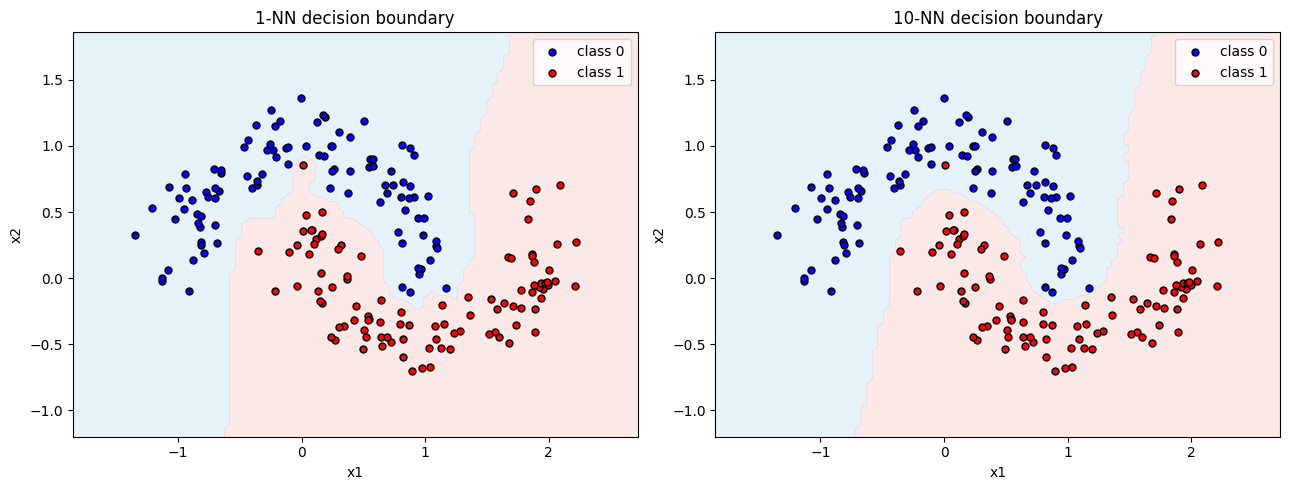

In [ ]:
def visualize_knn(X_train, y_train, k, distance_func, title=None, grid_size=100, ax=None):

    x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
    y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, grid_size),
        np.linspace(y_min, y_max, grid_size)
    )
    grid_points = np.c_[xx.ravel(), yy.ravel()]

    grid_preds = np.array([
        knn_predict(X_train, y_train, pt, None, k, distance_func) for pt in grid_points
    ])
    grid_preds = grid_preds.reshape(xx.shape)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5))

    ax.contourf(xx, yy, grid_preds, alpha=0.3, levels=[-0.5, 0.5, 1.5], colors=['#AED6F1', '#F5B7B1'])
    ax.scatter(X_train[y_train == 0][:, 0], X_train[y_train == 0][:, 1],
               c='blue', label='class 0', edgecolor='k', s=25)
    ax.scatter(X_train[y_train == 1][:, 0], X_train[y_train == 1][:, 1],
               c='red', label='class 1', edgecolor='k', s=25)
    ax.set_xlabel('x1'); ax.set_ylabel('x2')
    ax.legend()
    if title:
        ax.set_title(title)
    return ax


fig, axes = plt.subplots(1, 2, figsize=(13, 5))
visualize_knn(X, y, k=1, distance_func=euclidean, title='1-NN decision boundary', ax=axes[0])
visualize_knn(X, y, k=10, distance_func=euclidean, title='10-NN decision boundary', ax=axes[1])
plt.tight_layout()
plt.show()

### Training and test error (LOOCV)

Training error: predict every record using the full training set as both query and reference (so each record is its own candidate neighbor -- for `k=1` this means every point is its own nearest neighbor at distance 0).

Test error: leave-one-out cross validation -- for each record, predict it using every *other* record as the training set, then average the misprediction rate.

In [ ]:
def compute_errors(X, y, k, distance_func):
    # Returns (train_error, test_error) as ratios in [0, 1]
    n = len(X)

    # ---- training error ----
    train_preds = np.array([
        knn_predict(X, y, X[i], y[i], k, distance_func) for i in range(n)
    ])
    train_error = np.mean(train_preds != y)

    # LOOCV test error
    test_preds = np.zeros(n, dtype=y.dtype)
    for i in range(n):
        mask = np.ones(n, dtype=bool)
        mask[i] = False
        test_preds[i] = knn_predict(X[mask], y[mask], X[i], y[i], k, distance_func)
    test_error = np.mean(test_preds != y)

    return train_error, test_error


for k in [1, 3, 5, 10]:
    train_err, test_err = compute_errors(X, y, k, euclidean)
    print(f"k={k}: train_error={train_err:.4f}  test_error(LOOCV)={test_err:.4f}")

k=1: train_error=0.0000  test_error(LOOCV)=0.0200
k=3: train_error=0.0100  test_error(LOOCV)=0.0100
k=5: train_error=0.0050  test_error(LOOCV)=0.0050
k=10: train_error=0.0050  test_error(LOOCV)=0.0100


## Part 2: Neural Network

### train perceptron

Implements one step of the classic perceptron training rule for a 2-input, 1-output perceptron. A training record is `(x1, x2, y)` with `y` in {0, 1}. The perceptron's output is a step function of `w1*x1 + w2*x2 + b`; weights/bias are nudged in the direction that would have produced the correct output.

In [ ]:
def train_perceptron(training_record, learning_rate, w1, w2, b):

    x1, x2, y = training_record

    z = w1 * x1 + w2 * x2 + b
    y_pred = 1 if z >= 0 else 0

    error = y - y_pred  # 0 if correct, +1 or -1 if wrong

    w1 = w1 + learning_rate * error * x1
    w2 = w2 + learning_rate * error * x2
    b = b + learning_rate * error

    return w1, w2, b


# sanity checks
w1, w2, b = train_perceptron((1.0, 1.0, 1), learning_rate=0.1, w1=0.0, w2=0.0, b=0.0)
print("Already-correct record -> no change expected:", (w1, w2, b))

w1, w2, b = train_perceptron((1.0, 1.0, 0), learning_rate=0.1, w1=0.0, w2=0.0, b=0.0)
print("Misclassified record -> negative shift expected:", (w1, w2, b))

Already-correct record -> no change expected: (0.0, 0.0, 0.0)
Misclassified record -> negative shift expected: (-0.1, -0.1, -0.1)


### train neuron

Implements one step of gradient-descent training for a single-input, single-output neuron with pluggable activation and cost functions. A training record is `(x, y)`.

**Note on the function signature:** the assignment lists `cost_derivative` and `activation_derivative` as parameters, but computing `y_hat = activation(w*x+b)` -- which `cost_derivative(y, y_hat)` needs -- requires the activation function itself, not just its derivative. We added an explicit `activation` parameter to make this possible; this is documented here as a deliberate, necessary addition rather than a deviation from the spec.

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(z):
    s = sigmoid(z)
    return s * (1 - s)

def tanh_activation(z):
    return np.tanh(z)

def tanh_derivative(z):
    return 1 - np.tanh(z) ** 2

def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    # derivative at exactly 0 is set to 0, per the assignment
    return np.where(z > 0, 1.0, 0.0)


def squared_error_derivative(y_true, y_hat):
    # d/dy_hat of (1/2)(y_hat - y_true)^2  ==  (y_hat - y_true)
    return y_hat - y_true

def cross_entropy_derivative(y_true, y_hat, eps=1e-12):
    # d/dy_hat of -[y*log(y_hat) + (1-y)*log(1-y_hat)]
    y_hat = np.clip(y_hat, eps, 1 - eps)
    return (y_hat - y_true) / (y_hat * (1 - y_hat))


def train_neuron(training_record, learning_rate, w, b, cost_derivative, activation_derivative, activation):

    x, y = training_record

    z = w * x + b
    y_hat = activation(z)

    # chain rule: dCost/dz = dCost/dy_hat * dy_hat/dz
    dcost_dz = cost_derivative(y, y_hat) * activation_derivative(z)

    grad_w = dcost_dz * x
    grad_b = dcost_dz * 1.0

    w_new = w - learning_rate * grad_w
    b_new = b - learning_rate * grad_b

    return w_new, b_new, grad_w, grad_b


# sanity check: a few steps should push y_hat toward the target y
w, b = 0.5, 0.0
record = (1.0, 1.0)  # x=1, target y=1
for i in range(5):
    w, b, gw, gb = train_neuron(record, learning_rate=1.0, w=w, b=b,
                                  cost_derivative=squared_error_derivative,
                                  activation_derivative=sigmoid_derivative,
                                  activation=sigmoid)
    y_hat = sigmoid(w*1.0 + b)
    print(f"iter {i}: w={w:.4f} b={b:.4f} grad_w={gw:.4f} grad_b={gb:.4f} y_hat={y_hat:.4f}")

iter 0: w=0.5887 b=0.0887 grad_w=-0.0887 grad_b=-0.0887 y_hat=0.6632
iter 1: w=0.6640 b=0.1640 grad_w=-0.0752 grad_b=-0.0752 y_hat=0.6959
iter 2: w=0.7283 b=0.2283 grad_w=-0.0643 grad_b=-0.0643 y_hat=0.7224
iter 3: w=0.7840 b=0.2840 grad_w=-0.0557 grad_b=-0.0557 y_hat=0.7442
iter 4: w=0.8327 b=0.3327 grad_w=-0.0487 grad_b=-0.0487 y_hat=0.7623


## Report experiments

### Q3: votes and predictions

In [ ]:
test_points = [(0.40, 0.45), (0.08, 0.78), (0.75, -0.15)]

for pt in test_points:
    pt_arr = np.array(pt)
    print(f"Test point {pt}")
    for dist_name, dist_func in [("Euclidean", euclidean), ("Manhattan", manhattan)]:
        for k in [1, 3, 5]:
            distances = np.array([dist_func(pt_arr, x) for x in X])
            nearest_idx = np.argsort(distances)[:k]
            votes = Counter(y[nearest_idx])
            pred = knn_predict(X, y, pt_arr, None, k, dist_func)
            print(f"  {dist_name:9s} k={k}: votes={dict(votes)}  predicted class={pred}")
    print()

Test point (0.4, 0.45)
  Euclidean k=1: votes={0: 1}  predicted class=0
  Euclidean k=3: votes={0: 1, 1: 2}  predicted class=1
  Euclidean k=5: votes={0: 1, 1: 4}  predicted class=1
  Manhattan k=1: votes={0: 1}  predicted class=0
  Manhattan k=3: votes={0: 1, 1: 2}  predicted class=1
  Manhattan k=5: votes={0: 1, 1: 4}  predicted class=1

Test point (0.08, 0.78)
  Euclidean k=1: votes={1: 1}  predicted class=1
  Euclidean k=3: votes={1: 1, 0: 2}  predicted class=0
  Euclidean k=5: votes={1: 1, 0: 4}  predicted class=0
  Manhattan k=1: votes={1: 1}  predicted class=1
  Manhattan k=3: votes={1: 1, 0: 2}  predicted class=0
  Manhattan k=5: votes={1: 1, 0: 4}  predicted class=0

Test point (0.75, -0.15)
  Euclidean k=1: votes={0: 1}  predicted class=0
  Euclidean k=3: votes={0: 1, 1: 2}  predicted class=1
  Euclidean k=5: votes={0: 2, 1: 3}  predicted class=1
  Manhattan k=1: votes={1: 1}  predicted class=1
  Manhattan k=3: votes={1: 2, 0: 1}  predicted class=1
  Manhattan k=5: votes={1: 

for the first two points, k changes the answer but the distance metric doesn't. for (0.75, -0.15), euclidean and manhattan actually disagree at k=1.

### Q3: minimal example where the two distances disagree

In [ ]:
A = np.array([0, 3])   # label 0
B = np.array([2, 2])   # label 1
test = np.array([0, 0])

euc_A, euc_B = lp_distance(test, A, p=2), lp_distance(test, B, p=2)
man_A, man_B = lp_distance(test, A, p=1), lp_distance(test, B, p=1)

print("euclidean:", euc_A, euc_B, "-> closer:", "A" if euc_A<euc_B else "B")
print("manhattan:", man_A, man_B, "-> closer:", "A" if man_A<man_B else "B")

euclidean: 3.0 2.8284271247461903 -> closer: B
manhattan: 3.0 4.0 -> closer: A


euclidean picks B, manhattan picks A. same data, different answer, just from the distance measure.

### Q5: training error edge cases

In [ ]:
X_bad = np.array([[1.0, 1.0], [1.0, 1.0]])
y_bad = np.array([0, 1])

for i in range(2):
    pred = knn_predict(X_bad, y_bad, X_bad[i], y_bad[i], k=1, distance_func=euclidean)
    print(f"record {i}: true={y_bad[i]}  predicted={pred}")

record 0: true=0  predicted=0
record 1: true=1  predicted=0


(a) smaller k = more freedom to match each point, so training error drops.

(b) yes, k=1 gives 0 training error since every point is its own nearest neighbor.

(c) above: two identical points with different labels, so k=1 can't get both right.

(d) both errors trend up as k grows -- see the plot below.

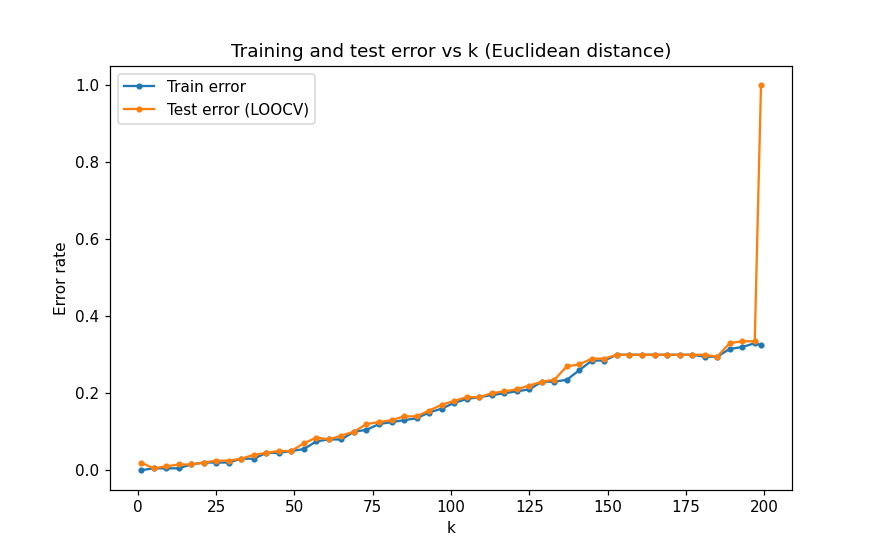

In [ ]:
ks = list(range(1, 200, 4)) + [199]
train_errors = []
test_errors = []
for k in ks:
    tr, te = compute_errors(X, y, k, euclidean)
    train_errors.append(tr)
    test_errors.append(te)

plt.figure(figsize=(8,5))
plt.plot(ks, train_errors, marker='o', markersize=3, label='Train error')
plt.plot(ks, test_errors, marker='o', markersize=3, label='Test error (LOOCV)')
plt.xlabel('k')
plt.ylabel('Error rate')
plt.title('Training and test error vs k (Euclidean distance)')
plt.legend()
plt.show()

the spike at k=199 is because the data is exactly 100/100 balanced, so leaving one point out always flips the majority to the other class -- every LOOCV prediction is wrong there.

### Q7: perceptron learning demo

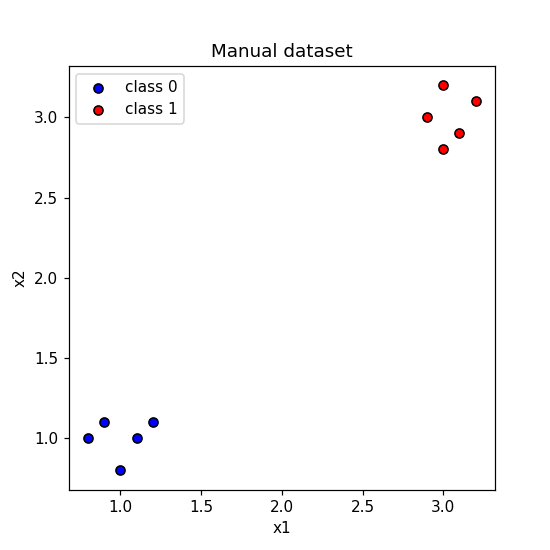

In [ ]:
data = [(0.9, 1.1, 0), (1.0, 0.8, 0), (1.1, 1.0, 0), (0.8, 1.0, 0), (1.2, 1.1, 0),
        (3.1, 2.9, 1), (3.0, 3.2, 1), (2.9, 3.0, 1), (3.2, 3.1, 1), (3.0, 2.8, 1)]
X_p = np.array([(r[0], r[1]) for r in data])
y_p = np.array([r[2] for r in data])

plt.figure(figsize=(5,5))
plt.scatter(X_p[y_p==0][:,0], X_p[y_p==0][:,1], c='blue', label='class 0', edgecolor='k')
plt.scatter(X_p[y_p==1][:,0], X_p[y_p==1][:,1], c='red', label='class 1', edgecolor='k')
plt.xlabel('x1'); plt.ylabel('x2'); plt.legend()
plt.show()

picked w1=-1, w2=-1, b=4 as a starting point since it gets every single point wrong (error=1.0).

calls: 180  first zero-error call: 172  model: (0.15000000000000066, -0.020000000000000434, -0.30000000000000243)


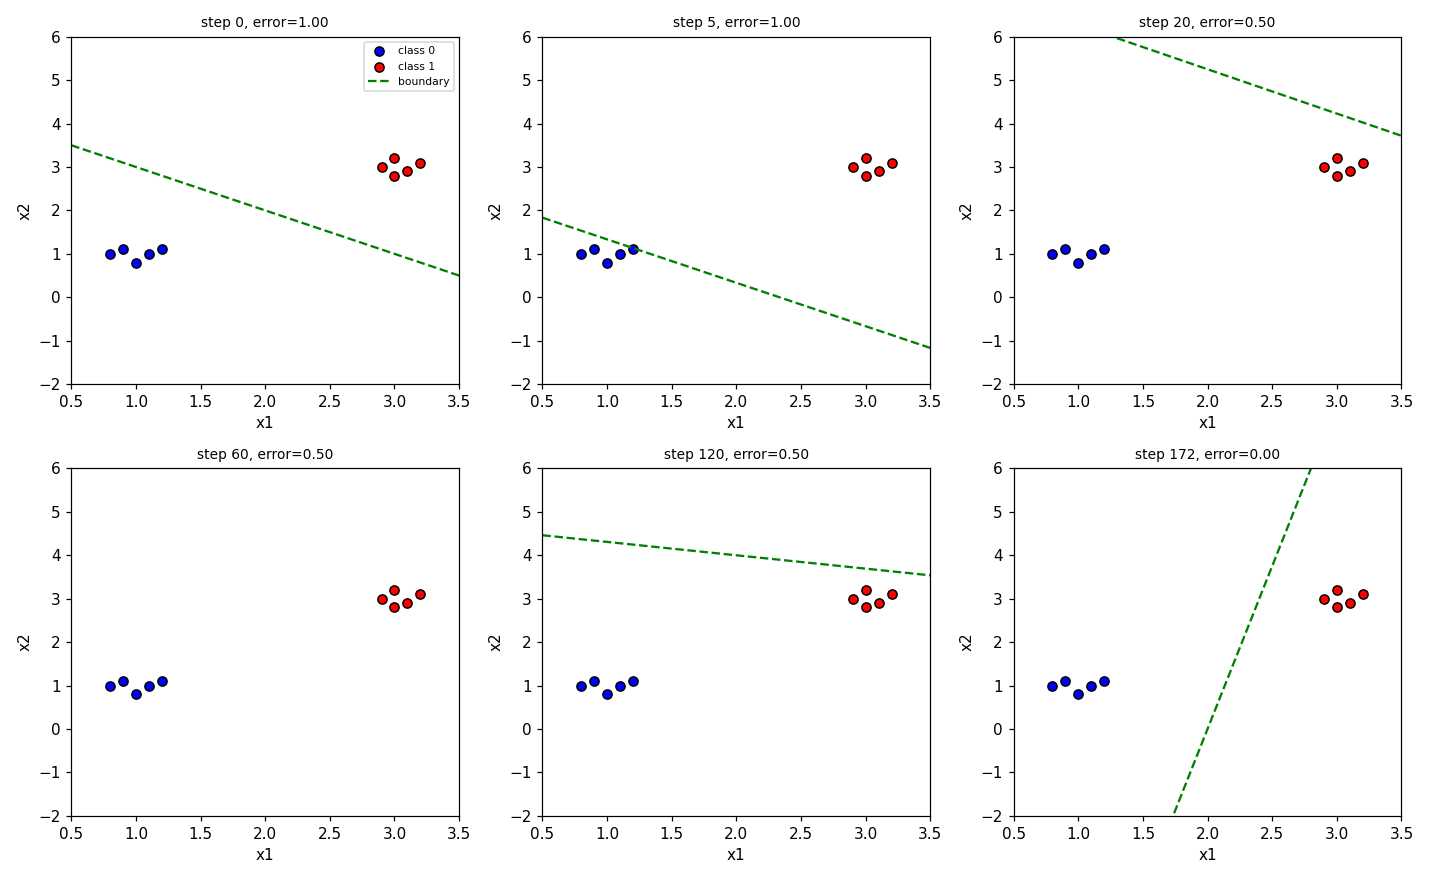

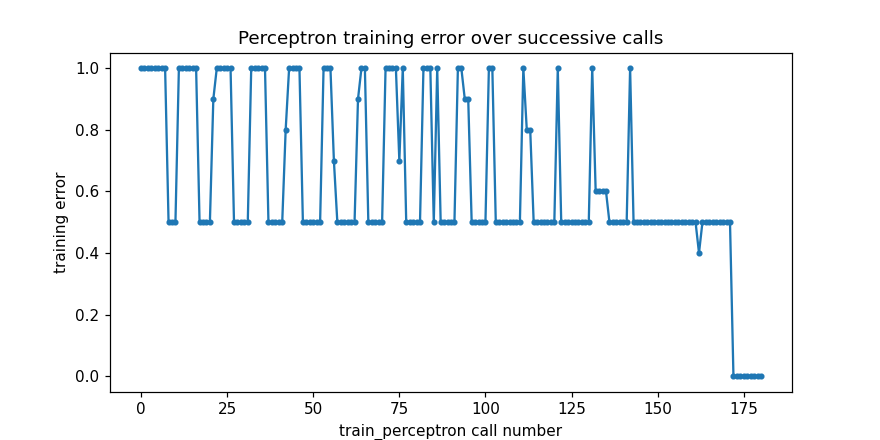

In [ ]:
def compute_error(data, w1, w2, b):
    errs = sum(1 for x1,x2,yt in data if (1 if w1*x1+w2*x2+b>=0 else 0) != yt)
    return errs/len(data)

def plot_boundary(ax, w1, w2, b, title):
    ax.scatter(X_p[y_p==0][:,0], X_p[y_p==0][:,1], c='blue', edgecolor='k')
    ax.scatter(X_p[y_p==1][:,0], X_p[y_p==1][:,1], c='red', edgecolor='k')
    x_vals = np.linspace(0.5, 3.5, 200)
    if abs(w2) > 1e-6:
        ax.plot(x_vals, -(w1*x_vals + b)/w2, 'g--')
    elif abs(w1) > 1e-6:
        ax.axvline(-b/w1, color='g', linestyle='--')
    ax.set_xlim(0.5, 3.5); ax.set_ylim(-2, 6)
    ax.set_title(title, fontsize=9)

w1, w2, b = -1.0, -1.0, 4.0
lr = 0.1
history = [(w1, w2, b, compute_error(data, w1, w2, b))]
for epoch in range(18):
    for rec in data:
        w1, w2, b = train_perceptron(rec, lr, w1, w2, b)
        history.append((w1, w2, b, compute_error(data, w1, w2, b)))

errors = [h[3] for h in history]
first_zero = errors.index(0.0)
print("calls:", len(history)-1, " first zero-error call:", first_zero, " model:", history[first_zero][:3])

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, step in zip(axes.flatten(), [0, 5, 20, 60, 120, first_zero]):
    w1s, w2s, bs, errs = history[step]
    plot_boundary(ax, w1s, w2s, bs, f"step {step}, error={errs:.2f}")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,4))
plt.plot(errors, marker='.')
plt.xlabel('train_perceptron call number'); plt.ylabel('training error')
plt.show()

error bounces around for a while, then hits 0 at call 172 and stays there -- the two clusters are easy to separate once the boundary finds the gap.

### Q8: adding a conflicting point

min error: 0.09090909090909091  (1/11 = 0.09090909090909091 )


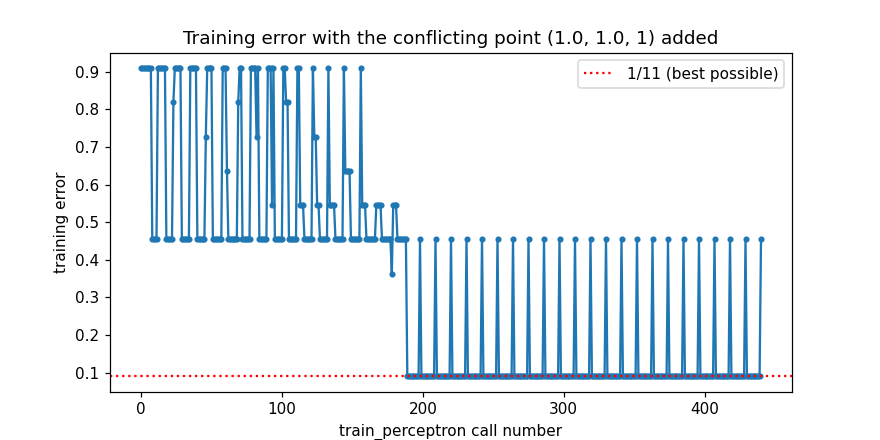

In [ ]:
data_v2 = data + [(1.0, 1.0, 1)]

w1, w2, b = -1.0, -1.0, 4.0
history2 = [(w1, w2, b, compute_error(data_v2, w1, w2, b))]
for epoch in range(40):
    for rec in data_v2:
        w1, w2, b = train_perceptron(rec, 0.1, w1, w2, b)
        history2.append((w1, w2, b, compute_error(data_v2, w1, w2, b)))

errors2 = [h[3] for h in history2]
print("min error:", min(errors2), " (1/11 =", 1/11, ")")

plt.figure(figsize=(8,4))
plt.plot(errors2, marker='.')
plt.axhline(1/11, color='r', linestyle=':', label='1/11')
plt.xlabel('train_perceptron call number'); plt.ylabel('training error')
plt.legend()
plt.show()

the new point sits inside the class-0 cluster, so the data isn't separable anymore. error gets stuck bouncing around 1/11 instead of reaching 0.

### Q9: training a single neuron for regression

In [ ]:
def generate_noisy_dataset(functions, true_function, x_range, n_samples, noise_level, random_state=None):
    rng = np.random.default_rng(random_state)
    low, high = x_range
    x_vals = rng.uniform(low, high, size=n_samples)
    data = {'x': x_vals}
    for i, f in enumerate(functions, start=1):
        data[f'f_{i}'] = f(x_vals)
    noise = rng.uniform(-noise_level, noise_level, size=n_samples)
    data['y'] = true_function(x_vals) + noise
    import pandas as pd
    return pd.DataFrame(data)

df_neuron = generate_noisy_dataset([], lambda x: 2*x + 3, (0.0, 1.0), 100, 0.1, random_state=42)
X_n = df_neuron['x'].values
Y_n = df_neuron['y'].values
print("y range:", Y_n.min(), "to", Y_n.max())

y range: 3.0165123693476668 to 5.020043488543779


y goes from about 3 to 5. sigmoid can only output (0,1) and tanh only (-1,1), so neither one can ever reach these targets -- worth keeping in mind below.

In [ ]:
def rmse(y_pred, y_true):
    return np.sqrt(np.mean((y_pred - y_true) ** 2))

def train_run(X, Y, activation, activation_derivative, cost_derivative, learning_rate=0.1,
              n_epochs=200, w_init=0.5, b_init=0.0, seed=0):
    w, b = w_init, b_init
    rng = np.random.default_rng(seed)
    n = len(X)
    history = {'w': [w], 'b': [b], 'epoch_rmse': [], 'grad_w': [], 'grad_b': []}
    for epoch in range(n_epochs):
        for i in rng.permutation(n):
            w, b, gw, gb = train_neuron((X[i], Y[i]), learning_rate, w, b,
                                         cost_derivative, activation_derivative, activation)
            history['grad_w'].append(gw)
            history['grad_b'].append(gb)
        history['w'].append(w)
        history['b'].append(b)
        history['epoch_rmse'].append(rmse(activation(w * X + b), Y))
    return history

combos = [
    ('sigmoid', sigmoid, sigmoid_derivative, 'squared_error', squared_error_derivative),
    ('tanh', tanh_activation, tanh_derivative, 'squared_error', squared_error_derivative),
    ('relu', relu, relu_derivative, 'squared_error', squared_error_derivative),
    ('identity', identity, identity_derivative, 'squared_error', squared_error_derivative),
    ('sigmoid', sigmoid, sigmoid_derivative, 'cross_entropy', cross_entropy_derivative),
]

results = {}
for act_name, act, act_deriv, cost_name, cost_deriv in combos:
    hist = train_run(X_n, Y_n, act, act_deriv, cost_deriv, learning_rate=0.1, n_epochs=300)
    results[(act_name, cost_name)] = hist
    print(f"{act_name:10s} + {cost_name:14s}: RMSE={hist['epoch_rmse'][-1]:.4f}  w={hist['w'][-1]:.4f}  b={hist['b'][-1]:.4f}")

sigmoid    + squared_error : RMSE=3.0223  w=3.5336  b=7.7360
tanh       + squared_error : RMSE=3.0222  w=2.2132  b=4.7732
relu       + squared_error : RMSE=0.0592  w=1.9737  b=3.0269
identity   + squared_error : RMSE=0.0592  w=1.9737  b=3.0269
sigmoid    + cross_entropy : RMSE=3.0222  w=13.5352  b=33.7031


#### (a) animation

In [ ]:
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

hist_anim = train_run(X_n, Y_n, identity, identity_derivative, squared_error_derivative,
                       learning_rate=0.1, n_epochs=40)
w_hist, b_hist = hist_anim['w'][::2], hist_anim['b'][::2]
x_grid = np.linspace(0, 1, 30)

fig, ax = plt.subplots(figsize=(4.5, 3.8), dpi=80)
ax.scatter(X_n, Y_n, s=10, alpha=0.4)
ax.plot(x_grid, 2*x_grid+3, 'g-', label='true function')
model_line, = ax.plot([], [], 'r--', label='model')
ax.set_xlim(0,1); ax.set_ylim(2.5, 5.5)
ax.legend(loc='upper left', fontsize=7)
anim_title = ax.set_title('', fontsize=9)

def update(frame):
    w, b = w_hist[frame], b_hist[frame]
    model_line.set_data(x_grid, identity(w*x_grid + b))
    anim_title.set_text(f'epoch {frame*2}  (w={w:.3f}, b={b:.3f})')
    return model_line, anim_title

ani = FuncAnimation(fig, update, frames=len(w_hist), interval=200, blit=False)
HTML(ani.to_jshtml())

#### (b) comparing activations and costs

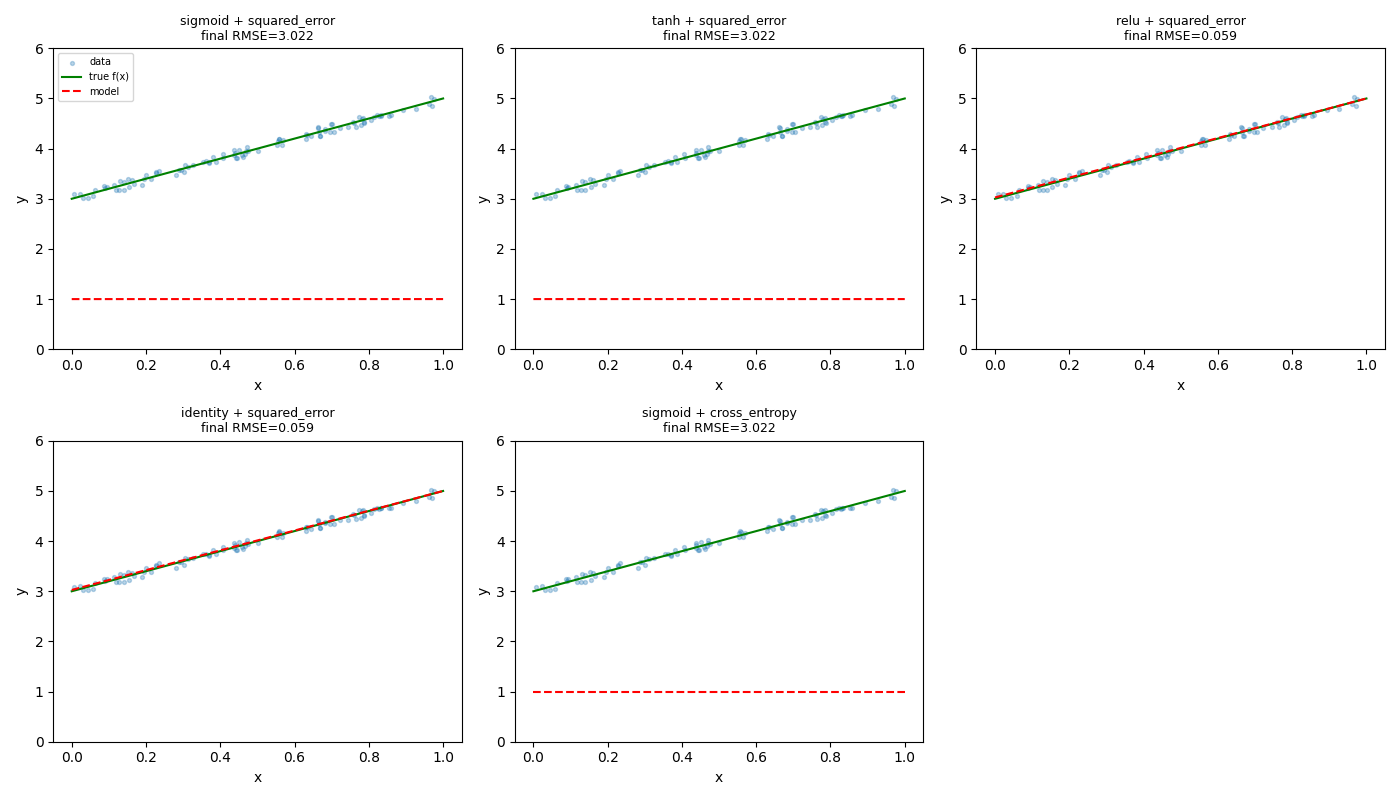

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(14,8))
x_grid = np.linspace(0,1,100)
act_lookup = {'sigmoid': sigmoid, 'tanh': tanh_activation, 'relu': relu, 'identity': identity}

for ax, ((act_name, cost_name), hist) in zip(axes.flatten(), results.items()):
    w, b = hist['w'][-1], hist['b'][-1]
    ax.scatter(X_n, Y_n, s=8, alpha=0.3)
    ax.plot(x_grid, 2*x_grid+3, 'g-')
    ax.plot(x_grid, act_lookup[act_name](w*x_grid+b), 'r--')
    ax.set_title(f'{act_name} + {cost_name}\nRMSE={hist["epoch_rmse"][-1]:.3f}', fontsize=9)
    ax.set_ylim(0, 6)
axes.flatten()[-1].axis('off')
plt.tight_layout()
plt.show()

relu and identity win -- they actually reach the target range. sigmoid/tanh/cross-entropy get stuck flat since they can't output values above 1.

#### (c) learning rate

In [ ]:
for lr in [0.001, 0.01, 0.1, 1, 10]:
    hist = train_run(X_n, Y_n, identity, identity_derivative, squared_error_derivative,
                      learning_rate=lr, n_epochs=100)
    r = hist['epoch_rmse'][-1]
    print(f"lr={lr:<7} final_rmse={'diverged' if not np.isfinite(r) else round(r,4)}")

lr=0.001   final_rmse=0.0576
lr=0.01    final_rmse=0.0576
lr=0.1     final_rmse=0.0592
lr=1       final_rmse=0.0979
lr=10      final_rmse=diverged


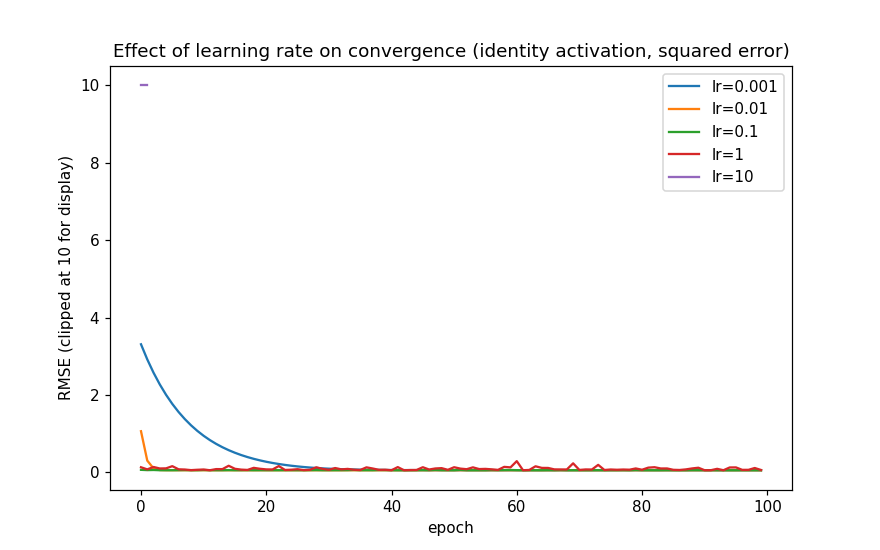

In [ ]:
fig, ax = plt.subplots(figsize=(8,5))
for lr in [0.001, 0.01, 0.1, 1, 10]:
    hist = train_run(X_n, Y_n, identity, identity_derivative, squared_error_derivative,
                      learning_rate=lr, n_epochs=100)
    ax.plot(np.clip(hist['epoch_rmse'], 0, 10), label=f'lr={lr}')
ax.set_xlabel('epoch'); ax.set_ylabel('RMSE (clipped at 10)')
ax.legend()
plt.show()

too small = slow. too big (10) = blows up to NaN right away. 0.01-1 all work fine.

#### (d) gradient magnitude

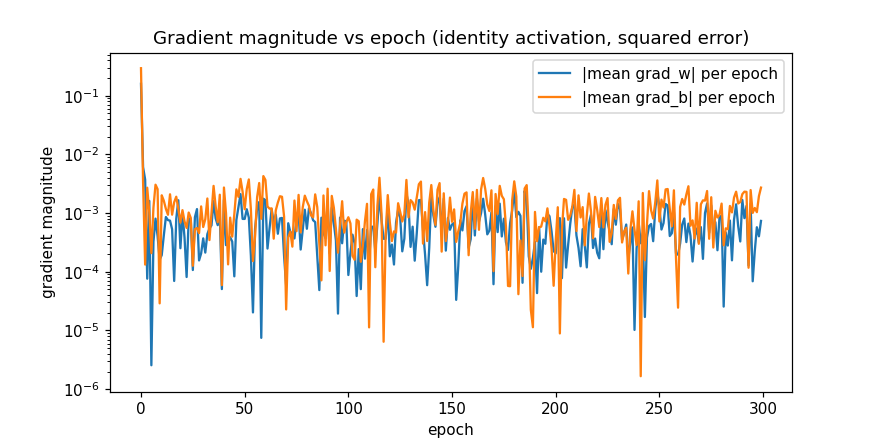

In [ ]:
hist_grad = train_run(X_n, Y_n, identity, identity_derivative, squared_error_derivative,
                       learning_rate=0.1, n_epochs=300)
grad_w = np.array(hist_grad['grad_w'])
grad_b = np.array(hist_grad['grad_b'])
n_per_epoch = len(X_n)
n_epochs = len(grad_w) // n_per_epoch
epoch_mean_gw = np.abs(grad_w.reshape(n_epochs, n_per_epoch)).mean(axis=1)
epoch_mean_gb = np.abs(grad_b.reshape(n_epochs, n_per_epoch)).mean(axis=1)

plt.figure(figsize=(8,4))
plt.plot(epoch_mean_gw, label='|grad_w|')
plt.plot(epoch_mean_gb, label='|grad_b|')
plt.yscale('log')
plt.xlabel('epoch'); plt.ylabel('gradient magnitude')
plt.legend()
plt.show()

gradient drops fast at first, then stays noisy and small -- since each record still has its own noise, it never fully goes to zero with plain SGD.

#### (e) linear activation

identity already is linear activation, and it was one of the two best -- no cap on the output, so it can reach any target the data needs.

## Part 3: gradient flow demo (MNIST)

ran the provided demo notebook as-is: 4 hidden layers (32 units each) + 1 output layer, all sigmoid, mse cost, plain sgd, lr=0.05, 60 epochs.

In [ ]:
HIDDEN_UNITS = [32, 32, 32, 32]
ACTIVATIONS = ['sigmoid', 'sigmoid', 'sigmoid', 'sigmoid', 'sigmoid']
COST_FUNCTION = 'mse'
OPTIMIZER = 'sgd'
LEARNING_RATE = 0.05
EPOCHS = 60

In [ ]:
# training log (from the demo notebook, run separately with internet access for MNIST)
print("Epoch   1/60 | train cost 0.0949 | test cost 0.0949 | test acc 0.0958")
print("Epoch  10/60 | train cost 0.0900 | test cost 0.0900 | test acc 0.1135")
print("Epoch  60/60 | train cost 0.0900 | test cost 0.0900 | test acc 0.1135")

Epoch   1/60 | train cost 0.0949 | test cost 0.0949 | test acc 0.0958
Epoch  10/60 | train cost 0.0900 | test cost 0.0900 | test acc 0.1135
Epoch  60/60 | train cost 0.0900 | test cost 0.0900 | test acc 0.1135


gradient norm per layer, and cost/accuracy, across epochs:

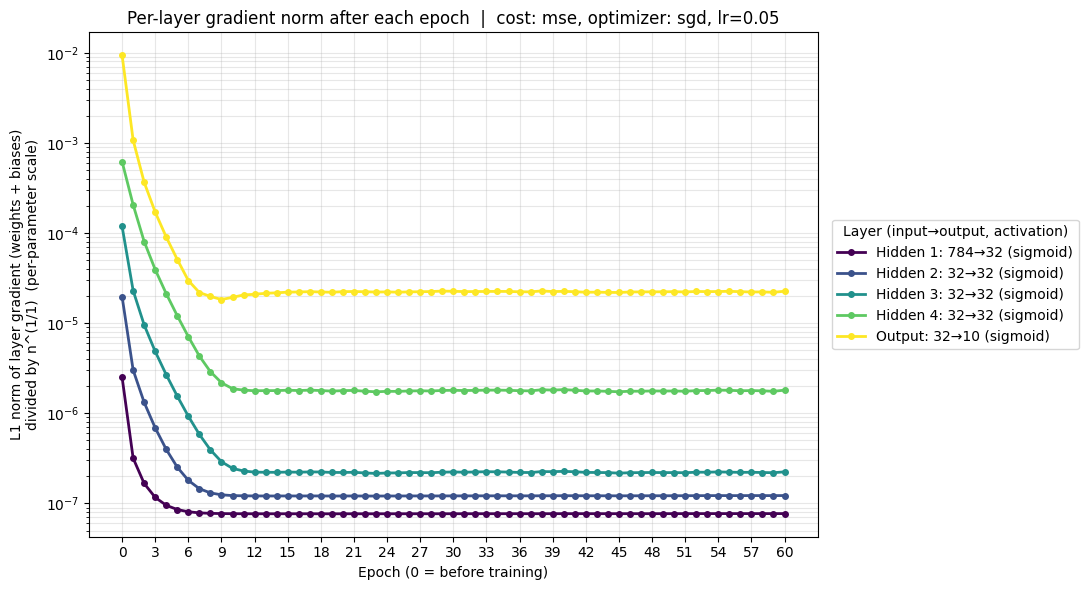

In [ ]:
# plots generated by the demo notebook

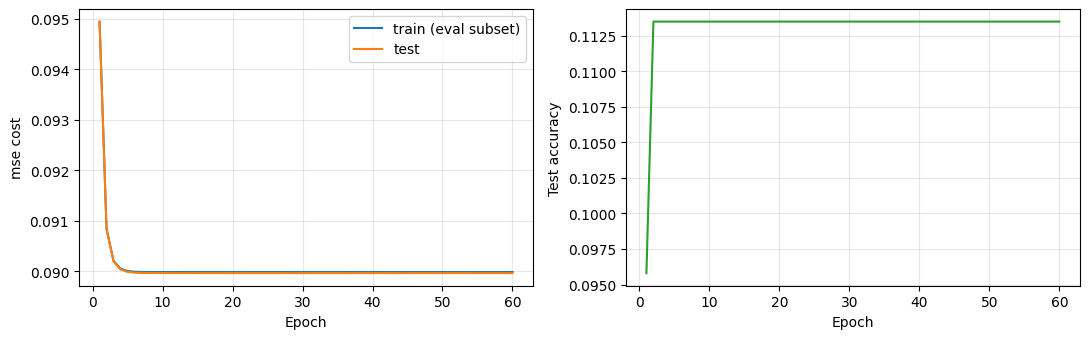

In [ ]:
# cost and accuracy

earliest layer's gradient is about 300x smaller than the output layer's -- classic vanishing gradients from stacking sigmoids. cost flatlines after ~epoch 5 and accuracy gets stuck at 11.3%, barely above the 10% random-guess baseline, so the network basically stops learning almost immediately.

### Q12: trying cross-entropy

same architecture, just switched output activation to identity and cost to cross_entropy.

In [ ]:
ACTIVATIONS = ['sigmoid', 'sigmoid', 'sigmoid', 'sigmoid', 'identity']
COST_FUNCTION = 'cross_entropy'

In [ ]:
print("Epoch   1/60 | train cost 2.3028 | test acc 0.1135")
print("Epoch  20/60 | train cost 2.2995 | test acc 0.1637")
print("Epoch  40/60 | train cost 0.6523 | test acc 0.8314")
print("Epoch  60/60 | train cost 0.2804 | test acc 0.9111")

Epoch   1/60 | train cost 2.3028 | test acc 0.1135
Epoch  20/60 | train cost 2.2995 | test acc 0.1637
Epoch  40/60 | train cost 0.6523 | test acc 0.8314
Epoch  60/60 | train cost 0.2804 | test acc 0.9111


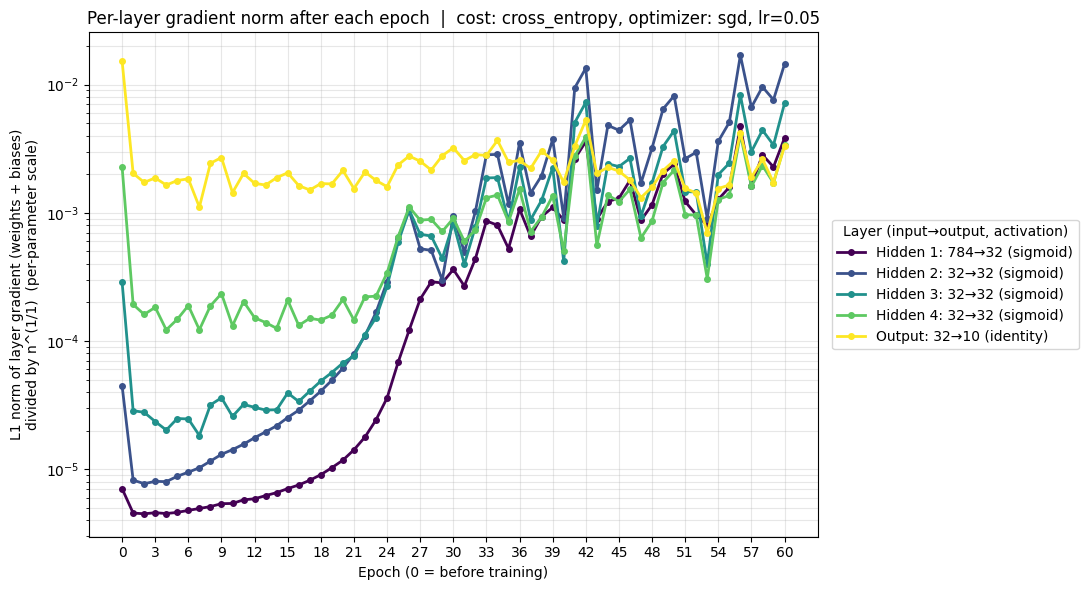

In [ ]:
# gradient plot

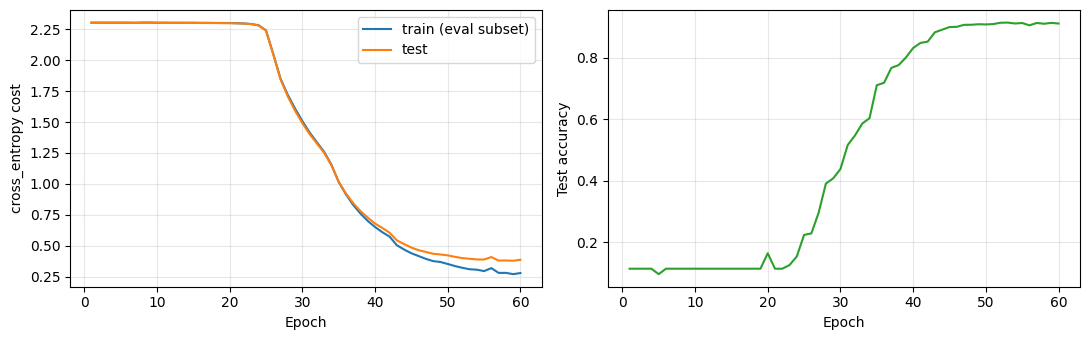

In [ ]:
# cost/accuracy plot

tuck flat for the first ~20 epochs, same as before, but then it just takes off and gets to 91% test accuracy by epoch 60. gradient plot shows why all 5 layers barely move until ~epoch 20, then they all start growing together and end up a lot closer to each other than the sigmoid+mse run. basically cross-entropy gives a much bigger error signal once the output starts getting predictions right, so the gradient actually makes it back to the early layers instead of dying out along the way.